In [17]:
from langgraph.graph import StateGraph, MessagesState, START, END
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel,Field
import operator
from typing import TypedDict,Annotated,Literal
from langchain_core.messages import SystemMessage,HumanMessage


load_dotenv()

True

In [4]:
generator_llm = ChatGoogleGenerativeAI(model='gemini-3.7-flash')
evaluator_llm = ChatGoogleGenerativeAI(model='gemini-3.7-flash')
optimizer_llm = ChatGoogleGenerativeAI(model='gemini-3.7-flash')

In [5]:
# state
class TweetState(TypedDict):

    topic: str
    tweet: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    tweet_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]
    
class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the tweet.")

In [ ]:
    structured_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [9]:
def generate_tweet(state: TweetState):
    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious tweet on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
"""),
    ]
    response = generator_llm.invoke(messages).content

    # return response
    return {"tweet": response, "tweet_history": [response]}

In [10]:
def evaluate_tweet(state: TweetState):

    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Twitter critic. You evaluate tweets based on humor, originality, virality, and tweet format."),
    HumanMessage(content=f"""
Evaluate the following tweet:

Tweet: "{state['tweet']}"

Use the criteria below to evaluate the tweet:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people retweet or share it?  
5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 280 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 280 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: One paragraph explaining the strengths and weaknesses 
""")
]

    response = structured_evaluator_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [11]:
def optimize_tweet(state: TweetState):

    messages = [
        SystemMessage(content="You punch up tweets for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the tweet based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Tweet:
{state['tweet']}

Re-write it as a short, viral-worthy tweet. Avoid Q&A style and stay under 280 characters.
""")
    ]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration, 'tweet_history': [response]}

In [12]:
def route_evaluation(state: TweetState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

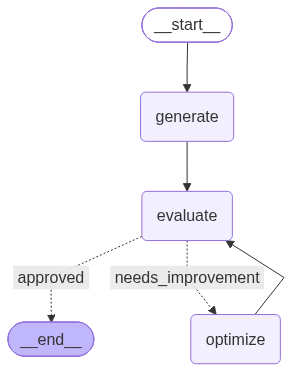

In [13]:
graph = StateGraph(TweetState)

graph.add_node('generate', generate_tweet)
graph.add_node('evaluate', evaluate_tweet)
graph.add_node('optimize', optimize_tweet)

graph.add_edge(START, 'generate')
graph.add_edge('generate', 'evaluate')

graph.add_conditional_edges('evaluate', route_evaluation, {'approved': END, 'needs_improvement': 'optimize'})
graph.add_edge('optimize', 'evaluate')

workflow = graph.compile()

workflow

In [16]:
initial_state = {
    "topic": "PM Modi",
    "iteration": 1,
    "max_iteration": 5
}
result = workflow.invoke(initial_state)


GoogleAPIError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [ ]:
result

{'topic': 'Diapers',
 'tweet': [{'type': 'text',
   'text': 'There is no extreme sport on earth that compares to the sheer panic of taking off a diaper, making direct eye contact with your baby, and realizing they are actively reloading.',
   'extras': {'signature': 'EuMbCuAbARFNMg8gdxjfEAklWdLqiHNK6WxPJSkVXdOjmG7ssQHOPEe8vDeDwJF6Cq8FGtGYzbgToc9syM1+uwzCx23KR1Uc2Hl+3I97RQmnzhx7IoQtJFaQ2ZsY+k3ASRtFPqN/yMTF2jjoUGz34/F5J54trBjBvD+b0mX55YHLdMxPnx1CapXJG794EhfGSSF5E+evx03Vhbad0mkABn2zffyc7FiAkGGTViqH+Qg7Ywy1Kt0bsux0FtTpe2Q1wvRYMuoTnMJswvHV8u3hdEzytggvlUCcBi/YYy/zK0Nv6C/RE6+/l97C/QLo4TfRxtcxkua76qXP9kS/GOdWPz4vr2RBFl5cmC8LwKyxwub40/JdqOf6RJl6VEAalrWZE8FoMCGL/Av5mAwwxRZuPdh9BZjVnWvYPQbIQYu8LNvyhpMOL4fv/Ar3tGv05b3p4mlyOuNC+A6gvCr3ih1nNiTekr4fUvyGx9o764pPlG1vHDltnw1/07snobrmlbQsKcNgjSzuXNjhqXgS3RdcKp+IskOJDTM25lyKz0N+lLzL2ji+GfJOofWhAKoLKRjgODEuD/VIghTiwczDuJT+bLpiLAIgWPHX4MMxSaYejCvvVJcNdV5gXqy9cOeFxBGaxd6mrw5A0Nb/e/BeKQ+00wbyID89diy9v8TK6xr1pf9twoJn3Wx8trS0rLByZTvuo5au4ZTH7yxikYTG/IFbneDMslxx